# 05 – BiLSTM
Mục tiêu: huấn luyện BiLSTM trên cùng split và cùng metric với baseline ML, rồi so sánh với SVM (Macro-F1 test = 0,7399).

Quy tắc xuyên suốt (giống notebook 04):
- Từ vựng chỉ lấy từ **train**.
- Chọn epoch và chọn cấu hình chỉ dựa trên **dev**.
- Tập **test chấm một lần**.
- Thứ tự lớp cố định: negative, neutral, positive.

## 1. Cài đặt, nạp dữ liệu

Mount Drive, nạp `data_clean.csv`, cố định seed. Hàm `set_seed` sẽ được gọi lại ở mỗi lần huấn luyện để các seed khác nhau cho kết quả khác nhau nhưng chạy lại cùng seed thì ra cùng kết quả.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, random
import numpy as np
import pandas as pd
import torch

PROJECT     = '/content/drive/MyDrive/project1_vsfc'
DATA_DIR    = f'{PROJECT}/data'
RESULTS_DIR = f'{PROJECT}/results'

SEED    = 42
LABELS  = ['negative', 'neutral', 'positive']
ID2NAME = {0: 'negative', 1: 'neutral', 2: 'positive'}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# --- Nạp dữ liệu ---
df = pd.read_csv(f'{DATA_DIR}/data_clean.csv', encoding='utf-8-sig', keep_default_na=False)
print('\nKích thước:', df.shape)
print('Các cột:', df.columns.tolist())

# --- Tách 3 tập ---
tr = df[df['split'] == 'train'].reset_index(drop=True)
dv = df[df['split'] == 'dev'].reset_index(drop=True)
te = df[df['split'] == 'test'].reset_index(drop=True)
y_tr, y_dv, y_te = tr['sentiment'].values, dv['sentiment'].values, te['sentiment'].values

cnt = pd.crosstab(df['split'], df['sentiment_name'])[LABELS].loc[['train', 'dev', 'test']]
print('\nSố câu theo lớp:')
print(cnt)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Thiết bị:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Kích thước: (16175, 6)
Các cột: ['split', 'text_raw', 'text_clean', 'text_seg', 'sentiment', 'sentiment_name']

Số câu theo lớp:
sentiment_name  negative  neutral  positive
split                                      
train               5325      458      5643
dev                  705       73       805
test                1409      167      1590
Thiết bị: cuda


## 2. Hàm đánh giá

Chép từ notebook 04 để số liệu của BiLSTM so sánh trực tiếp được với SVM / LR / NB:

- `evaluate`: Macro-F1 (metric chính), Accuracy, Precision / Recall / F1 từng lớp.
- `show_report`: báo cáo chi tiết từng lớp.
- `plot_cm`: ma trận nhầm lẫn (số câu và % theo hàng), thứ tự lớp cố định.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

LABEL_IDS = [0, 1, 2]          # tương ứng LABELS = negative, neutral, positive

def evaluate(y_true, y_pred, name='', split=''):
    """Trả về dict: Macro-F1 (chính), Accuracy, P/R/F1 từng lớp."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABEL_IDS, zero_division=0)
    row = {'model': name, 'split': split,
           'macro_f1': f1_score(y_true, y_pred, average='macro', labels=LABEL_IDS, zero_division=0),
           'accuracy': accuracy_score(y_true, y_pred)}
    for i, lab in enumerate(LABELS):
        row[f'P_{lab}'], row[f'R_{lab}'], row[f'F1_{lab}'] = p[i], r[i], f[i]
    return row

def show_report(y_true, y_pred):
    print(classification_report(y_true, y_pred, labels=LABEL_IDS,
                                target_names=LABELS, digits=4, zero_division=0))

def plot_cm(y_true, y_pred, title='', path=None):
    """Ma trận nhầm lẫn: số câu và % theo hàng (hàng = nhãn thật)."""
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_IDS)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i, j]}\n({cm_pct[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
                xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title(title)
    if path:
        plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()

## 3. Từ vựng, mã hóa câu, chia batch

Biến mỗi câu thành dãy số nguyên để đưa vào mô hình:

- **Từ vựng chỉ lấy từ train** (không nhìn dev và test, tránh rò rỉ). Từ xuất hiện ít hơn 2 lần trong train, hoặc chưa từng thấy ở dev/test, được đổi thành `<UNK>`. `<PAD>` (số 0) dùng để đệm các câu cho cùng độ dài trong một batch.
- **Độ dài tối đa 128 từ** (đã chốt ở notebook 03). Câu ngắn hơn không bị đệm cố định đến 128, mà chỉ đệm theo câu dài nhất trong batch (đệm động), nên chạy nhanh hơn.
- **Trọng số lớp** tính từ train theo công thức `n / (3 × số câu của lớp)`, tương đương `class_weight='balanced'` ở baseline ML, để so sánh công bằng.

In [ ]:
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

MAX_LEN  = 128
MIN_FREQ = 2
PAD, UNK = 0, 1
BATCH    = 64

def build_vocab(texts, min_freq=MIN_FREQ):
    cnt = Counter(w for s in texts for w in s.split())
    itos = ['<PAD>', '<UNK>'] + [w for w, c in cnt.most_common() if c >= min_freq]
    return {w: i for i, w in enumerate(itos)}, itos

def encode(s, stoi):
    return [stoi.get(w, UNK) for w in s.split()[:MAX_LEN]]

class TextDS(Dataset):
    def __init__(self, texts, labels, stoi):
        self.x = [encode(s, stoi) for s in texts]
        self.y = [int(v) for v in labels]
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        return self.x[i], self.y[i]

def collate(batch):
    xs   = [torch.tensor(x, dtype=torch.long) for x, _ in batch]
    lens = torch.tensor([len(x) for x in xs])
    X    = pad_sequence(xs, batch_first=True, padding_value=PAD)     # (batch, độ dài câu dài nhất)
    y    = torch.tensor([y for _, y in batch], dtype=torch.long)
    return X, lens, y

def make_loader(ds, shuffle, seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, collate_fn=collate,
                      generator=g if shuffle else None)
DATA = {}
for col in ['text_clean']:
    stoi, itos = build_vocab(tr[col])
    ds = {name: TextDS(d[col], d['sentiment'].values, stoi)
          for name, d in [('train', tr), ('dev', dv), ('test', te)]}
    DATA[col] = {'stoi': stoi, 'itos': itos, 'ds': ds}

# --- Thống kê từ vựng và từ lạ (OOV) ---
print('Kích thước từ vựng (đã gồm <PAD>, <UNK>):')
for col in DATA:
    print(f'  {col:10s}: {len(DATA[col]["stoi"]):,} từ')

# --- Trọng số lớp (tương đương class_weight='balanced') ---
cnt_y = np.bincount(y_tr, minlength=3)
CLASS_W = torch.tensor(len(y_tr) / (3 * cnt_y), dtype=torch.float)
print('\nTrọng số lớp (negative, neutral, positive):', CLASS_W.numpy().round(3))
assert abs(CLASS_W[1].item() - 8.316) < 0.01, 'Trọng số neutral lệch kỳ vọng'

Kích thước từ vựng (đã gồm <PAD>, <UNK>):
  text_clean: 1,526 từ

Trọng số lớp (negative, neutral, positive): [0.715 8.316 0.675]


## 4. Mô hình BiLSTM và vòng huấn luyện

**Mô hình** (cố định, không tinh chỉnh):
Embedding 128 chiều (khởi tạo ngẫu nhiên) → BiLSTM 1 lớp (hidden 128 mỗi chiều) → **max-pooling theo chiều thời gian** (lấy giá trị lớn nhất của mỗi chiều qua các từ, bỏ qua vị trí đệm) → dropout 0,5 → linear 3 lớp.

**Huấn luyện:**
- Loss: cross-entropy có trọng số lớp (`CLASS_W` ở ô 3).
- Adam, learning rate 1e-3, cắt gradient ở 1,0.
- **Dừng sớm theo Macro-F1 trên dev**: tối đa 20 epoch, dừng nếu 4 epoch liền không cải thiện, rồi nạp lại trọng số của epoch tốt nhất. Không dùng test ở bất cứ bước nào trong ô này.

[text_clean s42] epoch  1 | loss 0.8522 | dev Macro-F1 0.5977 | F1 neutral 0.2389 | 3.8s
[text_clean s42] epoch  2 | loss 0.6325 | dev Macro-F1 0.6630 | F1 neutral 0.2950 | 2.8s
[text_clean s42] epoch  3 | loss 0.5553 | dev Macro-F1 0.7034 | F1 neutral 0.3590 | 3.5s
[text_clean s42] epoch  4 | loss 0.5179 | dev Macro-F1 0.7511 | F1 neutral 0.4519 | 2.4s
[text_clean s42] epoch  5 | loss 0.4847 | dev Macro-F1 0.7114 | F1 neutral 0.3625 | 2.4s
[text_clean s42] epoch  6 | loss 0.4376 | dev Macro-F1 0.7406 | F1 neutral 0.4331 | 2.4s
[text_clean s42] epoch  7 | loss 0.4412 | dev Macro-F1 0.7716 | F1 neutral 0.4775 | 2.4s
[text_clean s42] epoch  8 | loss 0.4175 | dev Macro-F1 0.7526 | F1 neutral 0.4400 | 3.3s
[text_clean s42] epoch  9 | loss 0.3840 | dev Macro-F1 0.7731 | F1 neutral 0.4843 | 2.6s
[text_clean s42] epoch 10 | loss 0.3798 | dev Macro-F1 0.7623 | F1 neutral 0.4589 | 2.4s
[text_clean s42] epoch 11 | loss 0.3683 | dev Macro-F1 0.7736 | F1 neutral 0.4840 | 2.4s
[text_clean s42] epoc

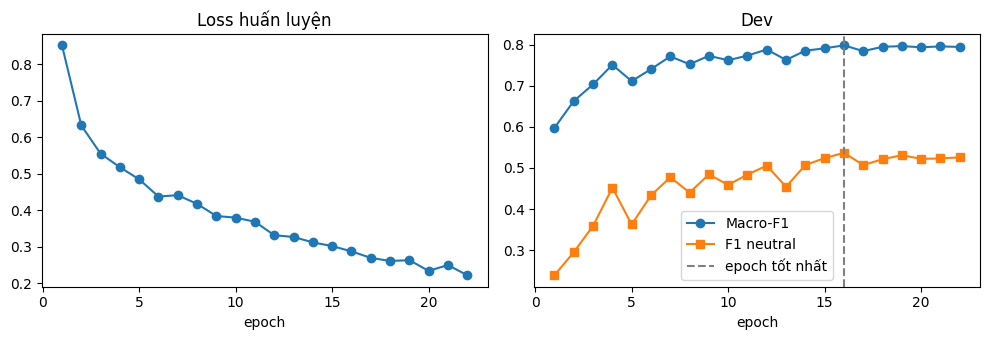


Báo cáo dev (epoch tốt nhất):
              precision    recall  f1-score   support

    negative     0.9462    0.8979    0.9214       705
     neutral     0.4359    0.6986    0.5368        73
    positive     0.9423    0.9329    0.9376       805

    accuracy                         0.9065      1583
   macro avg     0.7748    0.8431    0.7986      1583
weighted avg     0.9207    0.9065    0.9119      1583



In [ ]:
import copy
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

class BiLSTM(nn.Module):
    def __init__(self, vocab_size, emb=128, hid=128, drop=0.5):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.lstm = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.fc   = nn.Linear(2 * hid, 3)

    def forward(self, x, lens):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        out = out.masked_fill((x == PAD).unsqueeze(-1), -1e9)      # bỏ vị trí đệm khi lấy max
        pooled = out.max(dim=1).values
        return self.fc(self.drop(pooled))

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds = []
    for X, lens, _ in loader:
        preds.append(model(X.to(device), lens).argmax(1).cpu().numpy())
    return np.concatenate(preds)

def train_model(col, seed, max_epochs=40, patience=6, lr=1e-3, emb=128, hid=128, drop=0.5, verbose=True):
    """Huấn luyện, dừng sớm theo Macro-F1 dev, trả về mô hình tốt nhất + lịch sử."""
    set_seed(seed)
    D  = DATA[col]
    tl = make_loader(D['ds']['train'], shuffle=True, seed=seed)
    dl = make_loader(D['ds']['dev'], shuffle=False)
    model = BiLSTM(len(D['stoi']), emb, hid, drop).to(device)
    crit  = nn.CrossEntropyLoss(weight=CLASS_W.to(device))
    opt   = torch.optim.Adam(model.parameters(), lr=lr)

    hist, best, bad = [], {'f1': -1, 'epoch': 0, 'state': None}, 0
    for ep in range(1, max_epochs + 1):
        t0 = time.time()
        model.train()
        tot, n = 0.0, 0
        for X, lens, y in tl:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(X, lens), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(y)
            n += len(y)
        r = evaluate(y_dv, predict(model, dl))
        hist.append({'epoch': ep, 'train_loss': tot / n, 'dev_f1': r['macro_f1'], 'dev_f1_neutral': r['F1_neutral']})
        if verbose:
            print(f'[{col} s{seed}] epoch {ep:2d} | loss {tot / n:.4f} | dev Macro-F1 {r["macro_f1"]:.4f} '
                  f'| F1 neutral {r["F1_neutral"]:.4f} | {time.time() - t0:.1f}s')
        if r['macro_f1'] > best['f1']:
            best = {'f1': r['macro_f1'], 'epoch': ep,
                    'state': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best['state'])
    return {'model': model, 'hist': pd.DataFrame(hist), 'best_epoch': best['epoch'],
            'best_dev_f1': best['f1'], 'col': col, 'seed': seed}

# --- Chạy thử một lần ---
run = train_model('text_clean', SEED)
n_par = sum(p.numel() for p in run['model'].parameters())
print(f"\nTham số: {n_par:,} | epoch tốt nhất: {run['best_epoch']} | dev Macro-F1 tốt nhất: {run['best_dev_f1']:.4f}")

# --- Learning Curve ---
h = run['hist']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h['epoch'], h['train_loss'], marker='o'); ax[0].set_title('Loss huấn luyện'); ax[0].set_xlabel('epoch')
ax[1].plot(h['epoch'], h['dev_f1'], marker='o', label='Macro-F1')
ax[1].plot(h['epoch'], h['dev_f1_neutral'], marker='s', label='F1 neutral')
ax[1].axvline(run['best_epoch'], color='gray', ls='--', label='epoch tốt nhất')
ax[1].set_title('Dev'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

# --- Báo cáo dev tại epoch tốt nhất ---
print('\nBáo cáo dev (epoch tốt nhất):')
show_report(y_dv, predict(run['model'], make_loader(DATA['text_clean']['ds']['dev'], shuffle=False)))

## 5. Chạy nhiều seed (`text_clean`)

Giữ nguyên cấu hình ở ô 4, chỉ đổi seed (42 đến 46). Mỗi lần huấn luyện có dừng sớm theo Macro-F1 trên dev, rồi báo cáo trung bình ± độ lệch chuẩn.

Cần nhiều seed vì kết quả BiLSTM thay đổi theo khởi tạo trọng số và thứ tự batch, và dev chỉ có 73 câu neutral nên điểm dao động mạnh. Một lần chạy đơn lẻ có thể may hoặc rủi.

- Seed 42 được huấn luyện lại để kiểm tra tính tái lập: kết quả phải trùng ô 4 (dev Macro-F1 = 0,7986, epoch tốt nhất = 16).
- Cả 5 mô hình được lưu trong `RUNS` để ô chấm test dùng lại, không cần huấn luyện lại.
- Ô này chỉ chấm trên **dev**, chưa dùng test. Cấu hình (siêu tham số) không được chỉnh lại sau khi xem kết quả test.

In [ ]:
SEEDS = [42, 43, 44, 45, 46]
COL   = 'text_clean'

RUNS = {}
for s in SEEDS:
    RUNS[s] = train_model(COL, s, verbose=False)
    print(f"seed {s}: epoch tốt nhất {RUNS[s]['best_epoch']:2d} | dev Macro-F1 {RUNS[s]['best_dev_f1']:.4f}")

dev_loader = make_loader(DATA[COL]['ds']['dev'], shuffle=False)
rows = []
for s, r in RUNS.items():
    p = evaluate(y_dv, predict(r['model'], dev_loader), name=f'BiLSTM s{s}', split='dev')
    rows.append({'seed': s, 'best_epoch': r['best_epoch'], 'macro_f1': p['macro_f1'],
                 'accuracy': p['accuracy'], 'P_neutral': p['P_neutral'],
                 'R_neutral': p['R_neutral'], 'F1_neutral': p['F1_neutral']})
tab = pd.DataFrame(rows)

print('\nKết quả dev theo seed:')
print(tab.round(4).to_string(index=False))
print(f"\nDev Macro-F1 : {tab['macro_f1'].mean():.4f} ± {tab['macro_f1'].std():.4f}")
print(f"Dev F1 neutral: {tab['F1_neutral'].mean():.4f} ± {tab['F1_neutral'].std():.4f}")

seed 42: epoch tốt nhất 16 | dev Macro-F1 0.7986
seed 43: epoch tốt nhất 15 | dev Macro-F1 0.8049
seed 44: epoch tốt nhất 25 | dev Macro-F1 0.8043
seed 45: epoch tốt nhất 23 | dev Macro-F1 0.8102
seed 46: epoch tốt nhất 18 | dev Macro-F1 0.8166

Kết quả dev theo seed:
 seed  best_epoch  macro_f1  accuracy  P_neutral  R_neutral  F1_neutral
   42          16    0.7986    0.9065     0.4359     0.6986      0.5368
   43          15    0.8049    0.9122     0.4545     0.6849      0.5464
   44          25    0.8043    0.9179     0.5333     0.5479      0.5405
   45          23    0.8102    0.9179     0.5176     0.6027      0.5570
   46          18    0.8166    0.9198     0.5658     0.5890      0.5772

Dev Macro-F1 : 0.8069 ± 0.0068
Dev F1 neutral: 0.5516 ± 0.0162


## 6. Chấm test một lần, ma trận nhầm lẫn, so sánh với baseline ML

Đây là lần **duy nhất** dùng tập test cho BiLSTM. Dùng lại 5 mô hình đã huấn luyện ở ô 5 (`text_clean`, seed 42 đến 46, mỗi mô hình ở epoch tốt nhất theo dev), **không huấn luyện lại** và không chọn gì dựa vào test.

Nội dung:

1. Chấm test từng seed, báo cáo **trung bình ± độ lệch chuẩn** (một lần chạy BiLSTM không đủ tin cậy).
2. Bảng Precision / Recall / F1 từng lớp (trung bình 5 seed).
3. Ma trận nhầm lẫn **trung bình của 5 seed** (không chọn một seed theo test).
4. So sánh với SVM balanced, đọc số từ `ml_test_metrics.csv` do notebook 04 lưu, để không gõ tay.
5. Lưu bảng số liệu và hình cho báo cáo.

Quy tắc đọc kết quả (đặt trước khi xem): baseline chỉ có một lần chấm, không có khoảng tin cậy, và lớp neutral chỉ có 167 câu ở test nên điểm dao động mạnh. Vì vậy nếu trung bình BiLSTM chênh SVM **dưới 0,02 Macro-F1** thì viết "tương đương"; từ 0,02 trở lên mới viết hơn hoặc kém.

Kết quả test theo seed:
 seed  macro_f1  accuracy  P_neutral  R_neutral  F1_neutral  F1_negative  F1_positive
   42    0.7544    0.8803     0.3571     0.5689      0.4388       0.9031       0.9213
   43    0.7621    0.8888     0.3964     0.5269      0.4524       0.9099       0.9241
   44    0.7718    0.9005     0.5000     0.4431      0.4698       0.9174       0.9281
   45    0.7687    0.8973     0.4514     0.4731      0.4620       0.9186       0.9255
   46    0.7616    0.8945     0.4765     0.4251      0.4494       0.9146       0.9208

macro_f1    : 0.7637 ± 0.0068
accuracy    : 0.8923 ± 0.0080
F1_negative : 0.9127 ± 0.0063
F1_neutral  : 0.4545 ± 0.0119
F1_positive : 0.9239 ± 0.0030

P / R / F1 từng lớp (trung bình 5 seed):
          Precision  Recall      F1
negative     0.9129  0.9127  0.9127
neutral      0.4363  0.4874  0.4545
positive     0.9314  0.9167  0.9239


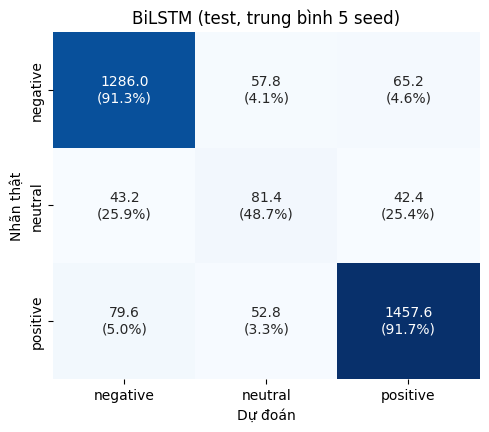

Neutral bị đoán sai: 85.6/167 (trung bình 5 seed)

So sánh trên test (SVM: TFIDF-uni + SVM (balanced)):
             SVM balanced  BiLSTM (TB 5 seed)  Chênh (BiLSTM - SVM)
macro_f1           0.7399              0.7637                0.0238
accuracy           0.8756              0.8923                0.0167
F1_negative        0.8971              0.9127                0.0156
F1_neutral         0.4119              0.4545                0.0426
F1_positive        0.9108              0.9239                0.0131
R_neutral          0.4551              0.4874                0.0323

Chênh Macro-F1 = +0.0238 (≥ 0,02): viết BiLSTM hơn SVM.


In [ ]:
test_loader = make_loader(DATA[COL]['ds']['test'], shuffle=False)

rows, cms = [], []
for s, r in RUNS.items():
    pred = predict(r['model'], test_loader)
    rows.append({'seed': s, **evaluate(y_te, pred, name=f'BiLSTM s{s}', split='test')})
    cms.append(confusion_matrix(y_te, pred, labels=LABEL_IDS))
te_tab = pd.DataFrame(rows)

# --- 1. Theo seed, trung bình ± độ lệch chuẩn ---
cols = ['seed', 'macro_f1', 'accuracy', 'P_neutral', 'R_neutral', 'F1_neutral', 'F1_negative', 'F1_positive']
print('Kết quả test theo seed:')
print(te_tab[cols].round(4).to_string(index=False))
print()
for c in ['macro_f1', 'accuracy', 'F1_negative', 'F1_neutral', 'F1_positive']:
    print(f'{c:12s}: {te_tab[c].mean():.4f} ± {te_tab[c].std():.4f}')

# --- 2. P / R / F1 từng lớp (trung bình 5 seed) ---
pr = pd.DataFrame({lab: [te_tab[f'{m}_{lab}'].mean() for m in ['P', 'R', 'F1']]
                   for lab in LABELS}, index=['Precision', 'Recall', 'F1']).T
print('\nP / R / F1 từng lớp (trung bình 5 seed):')
print(pr.round(4).to_string())

# --- 3. Ma trận nhầm lẫn trung bình ---
cm_mean = np.mean(cms, axis=0)
cm_pct  = np.mean([cm / cm.sum(axis=1, keepdims=True) * 100 for cm in cms], axis=0)
annot = np.array([[f'{cm_mean[i, j]:.1f}\n({cm_pct[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_mean, annot=annot, fmt='', cmap='Blues', cbar=False, xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title('BiLSTM (test, trung bình 5 seed)')
os.makedirs(RESULTS_DIR, exist_ok=True)
plt.savefig(f'{RESULTS_DIR}/fig_cm_bilstm_test.png', dpi=150, bbox_inches='tight')
plt.show()

neu_wrong = [int(cm[1].sum() - cm[1, 1]) for cm in cms]
print(f'Neutral bị đoán sai: {np.mean(neu_wrong):.1f}/{int(cms[0][1].sum())} (trung bình 5 seed)')

# --- 4. So sánh với SVM balanced (đọc từ notebook 04) ---
ml = pd.read_csv(f'{RESULTS_DIR}/ml_test_metrics.csv', encoding='utf-8-sig').iloc[0]
keys = ['macro_f1', 'accuracy', 'F1_negative', 'F1_neutral', 'F1_positive', 'R_neutral']
cmp = pd.DataFrame({
    'SVM balanced': [ml[k] for k in keys],
    'BiLSTM (TB 5 seed)': [te_tab[k].mean() for k in keys],
}, index=keys)
cmp['Chênh (BiLSTM - SVM)'] = cmp['BiLSTM (TB 5 seed)'] - cmp['SVM balanced']
print(f"\nSo sánh trên test (SVM: {ml['model']}):")
print(cmp.round(4).to_string())

gap = cmp.loc['macro_f1', 'Chênh (BiLSTM - SVM)']
if abs(gap) < 0.02:
    print(f'\nChênh Macro-F1 = {gap:+.4f} (< 0,02): viết "tương đương".')
else:
    print(f'\nChênh Macro-F1 = {gap:+.4f} (≥ 0,02): viết {"BiLSTM hơn" if gap > 0 else "BiLSTM kém"} SVM.')

# --- 5. Lưu ---
te_tab.round(4).to_csv(f'{RESULTS_DIR}/bilstm_test_metrics.csv', index=False, encoding='utf-8-sig')
cmp.round(4).to_csv(f'{RESULTS_DIR}/compare_ml_bilstm_test.csv', encoding='utf-8-sig')